# ε sweep: how much attack is left at smaller, less visible budgets?

Trains one universal perturbation per budget ε ∈ {4, 8, 16}/255 on SmolVLM-256M (same build set and recipe as notebook 01, 7 epochs, Adam with lr = ε/10). ε = 10/255 is loaded from notebook 01. Each v is evaluated through the **real pipeline** (saved as 8-bit, standard processor, splitting off) against random noise of the same ε, with a visibility measure (PSNR).

**Resumable:** each v is saved to Drive as soon as it is trained, and training is skipped for any ε whose file already exists. If Colab disconnects, just `Run all` again.

**Before running:** T4 GPU, then `Run all`. Rough estimate: 60–75 min (about 15 min of training per ε, then evaluation).

**Outputs:** the training log (section 4), the results table (section 5) and the figures (section 6), saved to `eps_sweep_results.json`, `eps_sweep.png` and `eps_visibility.png`.

## 1. Configuration

In [1]:
MODEL_ID   = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMG_SIZE   = 512
EPS_255    = [4, 8, 10, 16]                  # budgets on the 0-255 scale; 10 comes from notebook 01
N_BUILD    = 500
N_EVAL     = 200                             # captioned held-out images per budget
N_COS      = 50                              # held-out images for token cosine
EPOCHS     = 7                               # the first training run plateaued around epoch 7
BATCH      = 8
OUT_DIR    = "/content/drive/MyDrive/uap_smolvlm"
V10_PATH   = OUT_DIR + "/uap_smolvlm256m_linf10.npy"
CAPTION_SIM_CHANGED = 0.5
MAX_NEW_TOKENS = 40
P_DESCRIBE = "Describe this image in one sentence."
SEED = 0

## 2. Setup, data, model

In [2]:
!pip -q install "transformers>=4.50" sentence-transformers
import time, json, glob, random, tarfile, re
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")
DEVICE = "cuda"; assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = Path(OUT_DIR)

DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR = DATA_DIR / "imagenetv2-matched-frequency.tar.gz"
if not list(DATA_DIR.glob("imagenetv2-*/")):
    !wget -q --show-progress -O {TAR} https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz
    with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)
    TAR.unlink()
FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
perm = np.random.RandomState(SEED).permutation(len(FILES))
PREPROC = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
load = lambda fs: torch.stack([PREPROC(Image.open(f).convert("RGB")) for f in tqdm(fs, desc="decoding")])
B_u8 = load([FILES[i] for i in perm[:N_BUILD]])                       # same build set as in notebook 01
E_u8 = load([FILES[i] for i in perm[N_BUILD:N_BUILD + N_EVAL]])       # same held-out images as before

from transformers import AutoProcessor, AutoModelForImageTextToText
processor = AutoProcessor.from_pretrained(MODEL_ID); processor.tokenizer.padding_side = "left"
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE).eval()
for p in model.parameters(): p.requires_grad_(False)
VIS = model.model.vision_model
ip = processor.image_processor
MEAN = torch.tensor(ip.image_mean, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(ip.image_std,  device=DEVICE).view(1, 3, 1, 1)

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
def text_sim(a, b):
    ea = st.encode(a, convert_to_tensor=True, normalize_embeddings=True)
    eb = st.encode(b, convert_to_tensor=True, normalize_embeddings=True)
    return (ea * eb).sum(-1).cpu()

Mounted at /content/drive
/content/data/image 100%[===================>]   1.18G   118MB/s    in 13s     


/tmp/ipykernel_3098/417592157.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)


decoding:   0%|          | 0/500 [00:00<?, ?it/s]

decoding:   0%|          | 0/200 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

... (22 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 3. Helpers (same recipe as notebooks 01 and 03)

In [3]:
def to01(u8): return u8.to(DEVICE).float().div(255)
def norm(x01): return (x01 - MEAN) / STD
def visual_tokens(x01): return VIS(pixel_values=norm(x01)).last_hidden_state
def token_cosine(a, b): return F.cosine_similarity(a, b, dim=-1).mean(dim=1)

def train_uap(images_u8, xi, epochs=EPOCHS, bs=BATCH, tag=""):
    v = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([v], lr=xi / 10)                 # lr = eps/10 (= 1/255 at eps = 10/255, as in notebook 01)
    t0, n = time.time(), len(images_u8)
    for ep in range(epochs):
        losses = []
        for idx in torch.randperm(n).split(bs):
            x = to01(images_u8[idx])
            with torch.no_grad(): z0 = visual_tokens(x)
            loss = token_cosine(z0, visual_tokens((x + v).clamp(0, 1))).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad(): v.clamp_(-xi, xi)
            losses.append(loss.item())
        print(f"  {tag} epoch {ep+1}: mean token cosine on build set = {np.mean(losses):.3f}  ({(time.time()-t0)/60:.1f} min)")
    return v.detach().cpu()

def to_pil_u8(u8, pert=None):
    x = u8.float()
    if pert is not None: x = x + pert[0] * 255
    return Image.fromarray(x.round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy())

def chat(prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

@torch.no_grad()
def gen_pipeline(u8s, pert, bs=8):
    outs = []
    for i in range(0, len(u8s), bs):
        pils = [to_pil_u8(u, pert) for u in u8s[i:i+bs]]
        inp = processor(text=[chat(P_DESCRIBE)] * len(pils), images=[[p] for p in pils],
                        do_image_splitting=False, return_tensors="pt", padding=True).to(DEVICE)
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

@torch.no_grad()
def token_cos_pipeline(u8s, pert):
    cs = []
    for u in u8s:
        px = [processor.image_processor(images=[[to_pil_u8(u, p)]], do_image_splitting=False, return_tensors="pt")["pixel_values"][0].to(DEVICE)
              for p in (None, pert)]
        cs.append(token_cosine(VIS(pixel_values=px[0]).last_hidden_state, VIS(pixel_values=px[1]).last_hidden_state).item())
    return float(np.mean(cs))

@torch.no_grad()
def token_cos_after_preproc(u8s, pert, bs=16):        # after-preprocessing path (as in training), for comparison
    cs = []
    for i in range(0, len(u8s), bs):
        x = to01(u8s[i:i+bs]); cs.append(token_cosine(visual_tokens(x), visual_tokens((x + pert.to(DEVICE)).clamp(0, 1))).cpu())
    return torch.cat(cs).mean().item()

def psnr(u8s, pert):
    # visibility: PSNR (dB) between clean and perturbed 8-bit images; higher = less visible (>40 dB is usually invisible)
    vals = []
    for u in u8s:
        a = u.float(); b = torch.from_numpy(np.asarray(to_pil_u8(u, pert))).permute(2, 0, 1).float()
        mse = ((a - b) ** 2).mean().item(); vals.append(10 * np.log10(255 ** 2 / max(mse, 1e-10)))
    return float(np.mean(vals))

## 4. Train one v per budget (skipped if already on Drive)

In [4]:
V = {}
for e in EPS_255:
    path = Path(V10_PATH) if e == 10 else OUT / f"uap_smolvlm256m_linf{e}.npy"
    if path.exists():
        V[e] = torch.from_numpy(np.load(path)).float(); print(f"eps {e}/255: loaded {path.name}")
    else:
        print(f"eps {e}/255: training ({EPOCHS} epochs)")
        torch.manual_seed(SEED)
        V[e] = train_uap(B_u8, e / 255, tag=f"eps {e}")
        np.save(path, V[e].numpy()); print(f"  saved {path.name}")
    print(f"  ||v||_inf = {V[e].abs().max().item()*255:.2f}/255")

eps 4/255: training (7 epochs)
  eps 4 epoch 1: mean token cosine on build set = 0.753  (2.1 min)
  eps 4 epoch 2: mean token cosine on build set = 0.612  (4.3 min)
  eps 4 epoch 3: mean token cosine on build set = 0.572  (6.5 min)
  eps 4 epoch 4: mean token cosine on build set = 0.551  (8.7 min)
  eps 4 epoch 5: mean token cosine on build set = 0.538  (10.9 min)
  eps 4 epoch 6: mean token cosine on build set = 0.528  (13.1 min)
  eps 4 epoch 7: mean token cosine on build set = 0.521  (15.3 min)
  saved uap_smolvlm256m_linf4.npy
  ||v||_inf = 4.00/255
eps 8/255: training (7 epochs)
  eps 8 epoch 1: mean token cosine on build set = 0.597  (2.2 min)
  eps 8 epoch 2: mean token cosine on build set = 0.285  (4.4 min)
  eps 8 epoch 3: mean token cosine on build set = 0.158  (6.6 min)
  eps 8 epoch 4: mean token cosine on build set = 0.101  (8.8 min)
  eps 8 epoch 5: mean token cosine on build set = 0.069  (11.0 min)
  eps 8 epoch 6: mean token cosine on build set = 0.054  (13.2 min)
  eps

## 5. Evaluate every budget (real pipeline, splitting off)

In [5]:
t0 = time.time()
clean = gen_pipeline(E_u8, None)
RES = {"n_eval": N_EVAL, "n_cos": N_COS, "epochs": EPOCHS, "rows": {}, "captions": {"clean": clean}}
def person_share(caps): return float(np.mean([("person" in c.lower()) or ("white shirt" in c.lower()) for c in caps]))
for e in EPS_255:
    torch.manual_seed(SEED)
    pr = {"universal v": V[e], "random ±ξ": (e / 255) * torch.sign(torch.randn_like(V[e]))}
    row = {}
    for name, pert in pr.items():
        caps = gen_pipeline(E_u8, pert)
        sim = text_sim(clean, caps)
        row[name] = {"changed": (sim < CAPTION_SIM_CHANGED).float().mean().item(), "mean_sim": sim.mean().item(),
                     "token_cos_pipeline": token_cos_pipeline(E_u8[:N_COS], pert),
                     "token_cos_after_preproc": token_cos_after_preproc(E_u8[:N_COS], pert),
                     "person_or_white_shirt": person_share(caps), "psnr_db": psnr(E_u8[:N_COS], pert)}
        RES["captions"][f"{name} eps{e}"] = caps
    RES["rows"][e] = row
    with open(OUT / "eps_sweep_results.json", "w") as f: json.dump(RES, f, indent=1, default=float)
    print(f"eps {e}/255 evaluated ({(time.time()-t0)/60:.1f} min)")

print(f"\n{N_EVAL} held-out images, real pipeline; token cosine on {N_COS} images. Clean captions mentioning a person/white shirt: {person_share(clean):.0%}\n")
hdr = f"{'eps':>6s} {'condition':12s}{'captions changed':>17s}{'token cos (pipeline)':>22s}{'token cos (preproc)':>25s}{'person/shirt':>14s}{'PSNR dB':>9s}"
print(hdr); print("-" * len(hdr))
for e in EPS_255:
    for name in ["universal v", "random ±ξ"]:
        r = RES["rows"][e][name]
        print(f"{e:>4d}/255 {name:12s}{r['changed']:>17.1%}{r['token_cos_pipeline']:>22.3f}{r['token_cos_after_preproc']:>25.3f}"
              f"{r['person_or_white_shirt']:>14.0%}{r['psnr_db']:>9.1f}")

/tmp/ipykernel_3098/3800973916.py:62: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  a = u.float(); b = torch.from_numpy(np.asarray(to_pil_u8(u, pert))).permute(2, 0, 1).float()


eps 4/255 evaluated (3.8 min)
eps 8/255 evaluated (6.4 min)
eps 10/255 evaluated (9.0 min)
eps 16/255 evaluated (11.5 min)

200 held-out images, real pipeline; token cosine on 50 images. Clean captions mentioning a person/white shirt: 11%

   eps condition    captions changed  token cos (pipeline)      token cos (preproc)  person/shirt  PSNR dB
----------------------------------------------------------------------------------------------------------
   4/255 universal v             21.5%                 0.623                    0.531           14%     37.0
   4/255 random ±ξ                1.0%                 0.962                    0.956           14%     36.2
   8/255 universal v             62.5%                 0.291                    0.070           22%     32.0
   8/255 random ±ξ                3.5%                 0.895                    0.878           13%     30.2
  10/255 universal v             71.5%                 0.142                   -0.062           28%     30.1
 

## 6. Figures

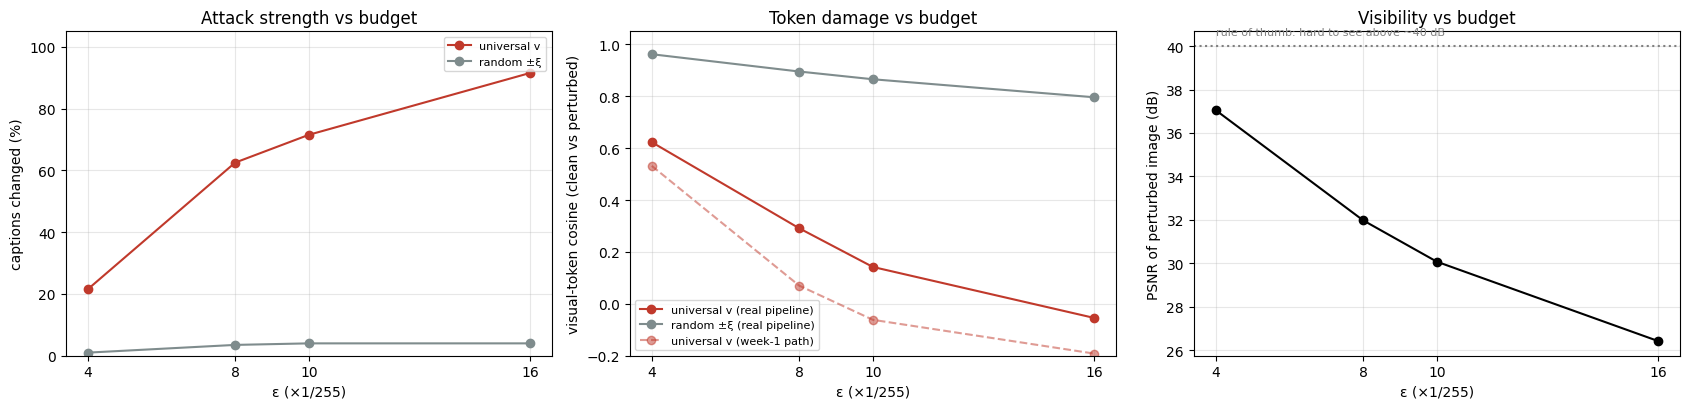

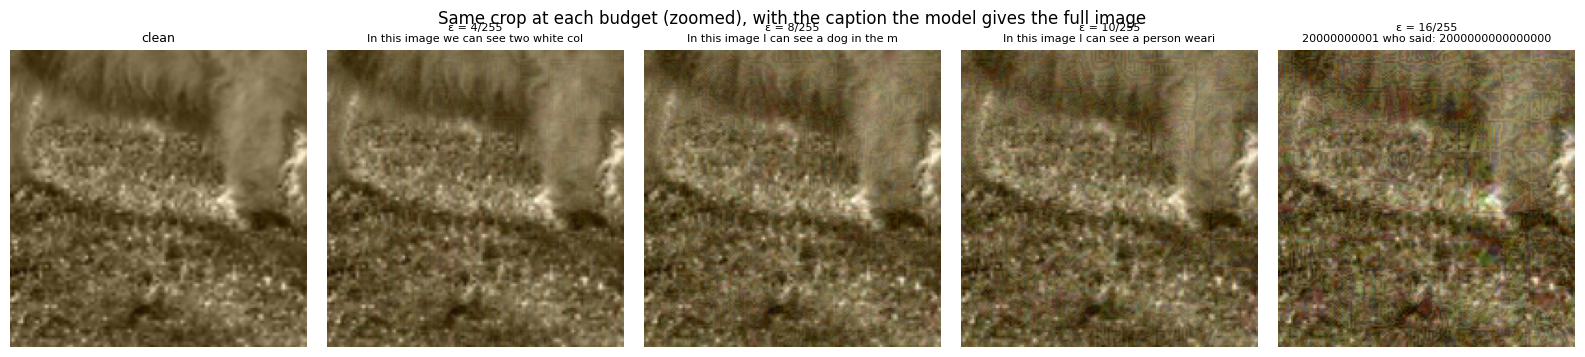

clean caption: In this image we can see two dogs.


In [6]:
E = EPS_255; COL = {"universal v": "#c0392b", "random ±ξ": "#7f8c8d"}
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
for name in ["universal v", "random ±ξ"]:
    axs[0].plot(E, [100 * RES["rows"][e][name]["changed"] for e in E], "o-", color=COL[name], label=name)
    axs[1].plot(E, [RES["rows"][e][name]["token_cos_pipeline"] for e in E], "o-", color=COL[name], label=name + " (real pipeline)")
axs[1].plot(E, [RES["rows"][e]["universal v"]["token_cos_after_preproc"] for e in E], "o--", color=COL["universal v"], alpha=.5, label="universal v (after preprocessing)")
axs[2].plot(E, [RES["rows"][e]["universal v"]["psnr_db"] for e in E], "o-", color="k")
axs[2].axhline(40, ls=":", color="gray"); axs[2].text(E[0], 40.5, "rule of thumb: hard to see above ~40 dB", fontsize=8, color="gray")
for ax, yl, t in [(axs[0], "captions changed (%)", "Attack strength vs budget"),
                  (axs[1], "visual-token cosine (clean vs perturbed)", "Token damage vs budget"),
                  (axs[2], "PSNR of perturbed image (dB)", "Visibility vs budget")]:
    ax.set_xlabel("ε (×1/255)"); ax.set_ylabel(yl); ax.set_title(t); ax.set_xticks(E); ax.grid(alpha=.3)
axs[0].set_ylim(0, 105); axs[1].set_ylim(-0.2, 1.05); axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "eps_sweep.png", dpi=150); plt.show()

# Visibility close-up: the same 160x160 crop (flat area) at each budget
idx = 1                                   # the two-dogs image (grass): change if the crop shows no flat area
u = E_u8[idx]; y0, x0 = 330, 40
fig, ax = plt.subplots(1, len(E) + 1, figsize=(3.2 * (len(E) + 1), 3.6))
ax[0].imshow(u.permute(1, 2, 0)[y0:y0+160, x0:x0+160]); ax[0].set_title("clean", fontsize=9)
for j, e in enumerate(E):
    ax[j+1].imshow(np.asarray(to_pil_u8(u, V[e]))[y0:y0+160, x0:x0+160])
    ax[j+1].set_title(f"ε = {e}/255\n{RES['captions'][f'universal v eps{e}'][idx][:38]}", fontsize=8)
for a in ax: a.axis("off")
plt.suptitle("Same crop at each budget (zoomed), with the caption the model gives the full image")
plt.tight_layout(); plt.savefig(OUT / "eps_visibility.png", dpi=150); plt.show()
print("clean caption:", clean[idx])